# 02 — Data Analysis & Visualization

**Goal:** explore operational patterns and relationships using charts. All plots are generated from the dataset at runtime.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data" / "raw").exists() and (ROOT.parent / "data" / "raw").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "raw" / "dynamic_supply_chain_logistics_dataset.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. Open this notebook from the project root "
        "or update DATA_PATH to the CSV location."
    )

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)

Dataset shape: (32065, 26)


## 1. Target and risk distributions

In [2]:
print(df.shape)
print(df.columns.tolist())

print(df["risk_classification"].value_counts())
print(df["order_fulfillment_status"].value_counts())

(32065, 26)
['timestamp', 'vehicle_gps_latitude', 'vehicle_gps_longitude', 'fuel_consumption_rate', 'eta_variation_hours', 'traffic_congestion_level', 'warehouse_inventory_level', 'loading_unloading_time', 'handling_equipment_availability', 'order_fulfillment_status', 'weather_condition_severity', 'port_congestion_level', 'shipping_costs', 'supplier_reliability_score', 'lead_time_days', 'historical_demand', 'iot_temperature', 'cargo_condition_status', 'route_risk_level', 'customs_clearance_time', 'driver_behavior_score', 'fatigue_monitoring_score', 'disruption_likelihood_score', 'delay_probability', 'risk_classification', 'delivery_time_deviation']
risk_classification
High Risk        23944
Moderate Risk     5011
Low Risk          3110
Name: count, dtype: int64
order_fulfillment_status
0.761166    1
0.196594    1
0.152742    1
0.811885    1
0.053659    1
           ..
0.992997    1
0.946031    1
0.437687    1
0.517051    1
0.985761    1
Name: count, Length: 32065, dtype: int64


In [3]:
import matplotlib.pyplot as plt

<function matplotlib.pyplot.show(close=None, block=None)>

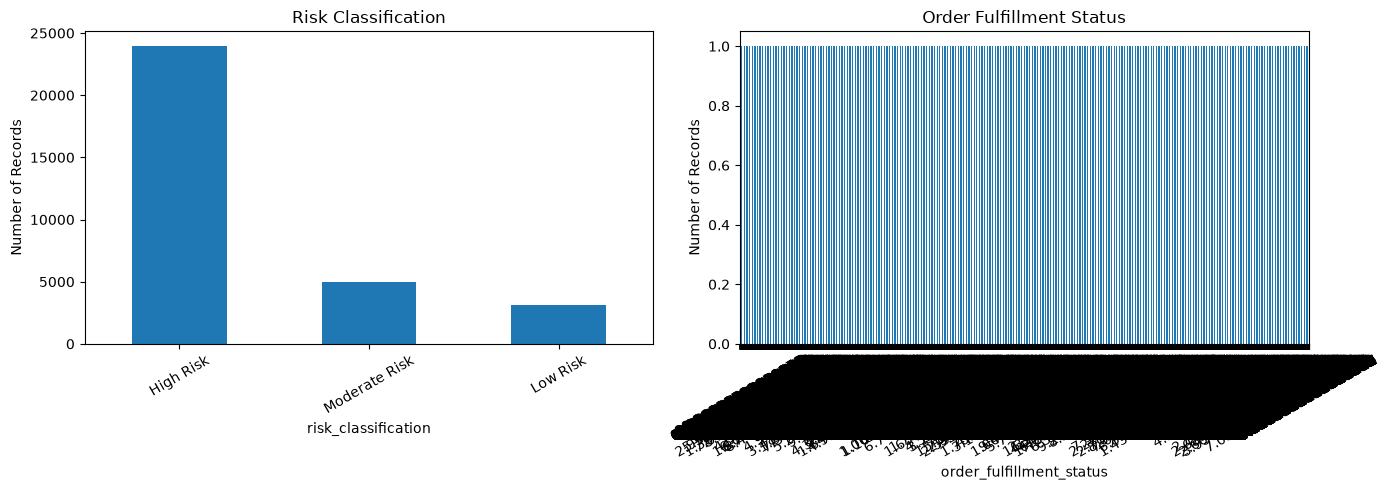

In [10]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
df["risk_classification"].value_counts().plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("Risk Classification")
axes[0].set_ylabel("Number of Records")
axes[0].tick_params(axis="x", rotation=30)

df["order_fulfillment_status"].value_counts().plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Order Fulfillment Status")
axes[1].set_ylabel("Number of Records")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show


## 2. Temperature distribution

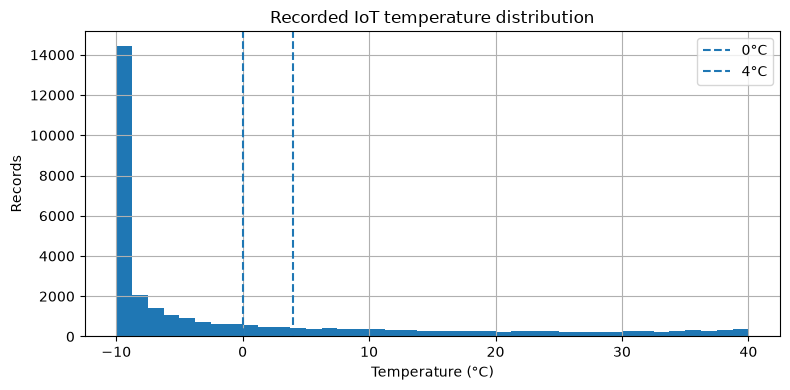

,records
iot_temperature,
Below 0°C,21817
Above 4°C,8674
0–4°C,1574


In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
df["iot_temperature"].hist(bins=40, ax=ax)
ax.axvline(0, linestyle="--", label="0°C")
ax.axvline(4, linestyle="--", label="4°C")
ax.set(title="Recorded IoT temperature distribution", xlabel="Temperature (°C)", ylabel="Records")
ax.legend()
plt.tight_layout()
plt.show()

temperature_groups = pd.cut(
    df["iot_temperature"],
    [-np.inf, 0, 4, np.inf],
    labels=["Below 0°C", "0–4°C", "Above 4°C"]
)
display(temperature_groups.value_counts().to_frame("records"))

## 3. Delay and disruption score distributions

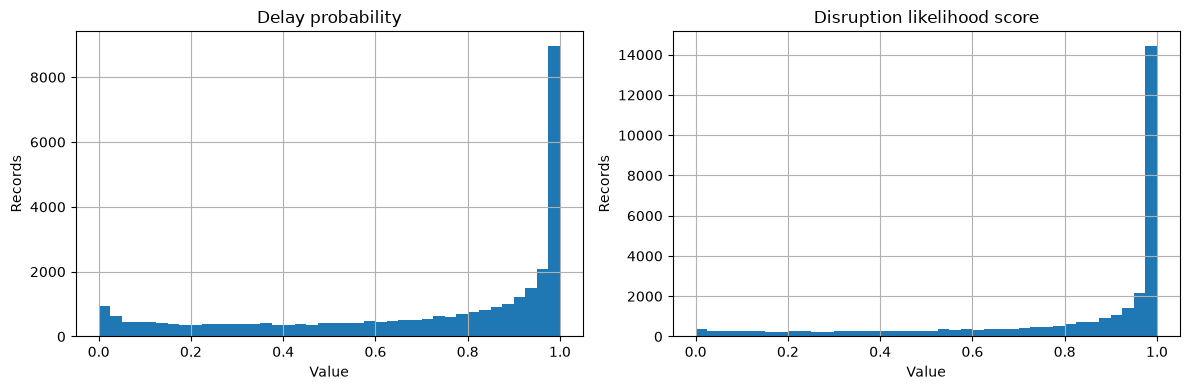

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["delay_probability"].hist(bins=40, ax=axes[0])
axes[0].set(title="Delay probability", xlabel="Value", ylabel="Records")
df["disruption_likelihood_score"].hist(bins=40, ax=axes[1])
axes[1].set(title="Disruption likelihood score", xlabel="Value", ylabel="Records")
plt.tight_layout()
plt.show()

## 4. Correlations — numeric fields

,vehicle_gps_latitude,vehicle_gps_longitude,fuel_consumption_rate,eta_variation_hours,traffic_congestion_level,warehouse_inventory_level,loading_unloading_time,handling_equipment_availability,order_fulfillment_status,weather_condition_severity,...,historical_demand,iot_temperature,cargo_condition_status,route_risk_level,customs_clearance_time,driver_behavior_score,fatigue_monitoring_score,disruption_likelihood_score,delay_probability,delivery_time_deviation
vehicle_gps_latitude,1.00,0.01,-0.00,0.00,-0.00,0.00,0.00,-0.00,0.01,0.01,...,0.00,-0.00,-0.00,-0.01,0.00,-0.01,-0.01,-0.01,-0.01,0.00
vehicle_gps_longitude,0.01,1.00,-0.00,0.00,-0.01,-0.00,-0.01,-0.00,0.00,0.01,...,-0.01,0.01,0.00,0.00,-0.00,-0.01,0.00,0.00,-0.01,-0.00
fuel_consumption_rate,-0.00,-0.00,1.00,0.00,0.01,0.00,0.00,0.01,-0.00,-0.01,...,-0.00,0.01,0.00,0.01,0.00,-0.00,-0.00,0.00,-0.01,0.01
eta_variation_hours,0.00,0.00,0.00,1.00,-0.00,0.00,-0.00,-0.00,-0.01,0.01,...,0.01,-0.00,0.00,-0.01,-0.00,0.00,0.01,0.00,-0.01,-0.00
traffic_congestion_level,-0.00,-0.01,0.01,-0.00,1.00,0.01,-0.01,-0.00,-0.00,0.00,...,0.00,0.01,-0.00,0.01,-0.00,-0.00,0.01,0.00,-0.00,0.00
warehouse_inventory_level,0.00,-0.00,0.00,0.00,0.01,1.00,0.00,-0.01,-0.01,-0.01,...,0.00,0.00,0.00,0.00,-0.01,0.00,-0.01,-0.01,0.00,-0.01
loading_unloading_time,0.00,-0.01,0.00,-0.00,-0.01,0.00,1.00,0.01,0.00,0.00,...,-0.01,0.00,-0.00,-0.00,0.01,-0.00,0.00,0.00,-0.00,0.00
handling_equipment_availability,-0.00,-0.00,0.01,-0.00,-0.00,-0.01,0.01,1.00,-0.00,0.00,...,-0.00,-0.01,-0.00,-0.00,-0.01,0.01,-0.01,0.00,0.00,-0.00
order_fulfillment_status,0.01,0.00,-0.00,-0.01,-0.00,-0.01,0.00,-0.00,1.00,0.00,...,0.00,0.00,0.01,0.00,-0.01,0.00,-0.00,-0.01,0.01,0.00
weather_condition_severity,0.01,0.01,-0.01,0.01,0.00,-0.01,0.00,0.00,0.00,1.00,...,-0.01,0.00,-0.00,-0.01,0.00,-0.01,0.00,-0.00,0.00,-0.00


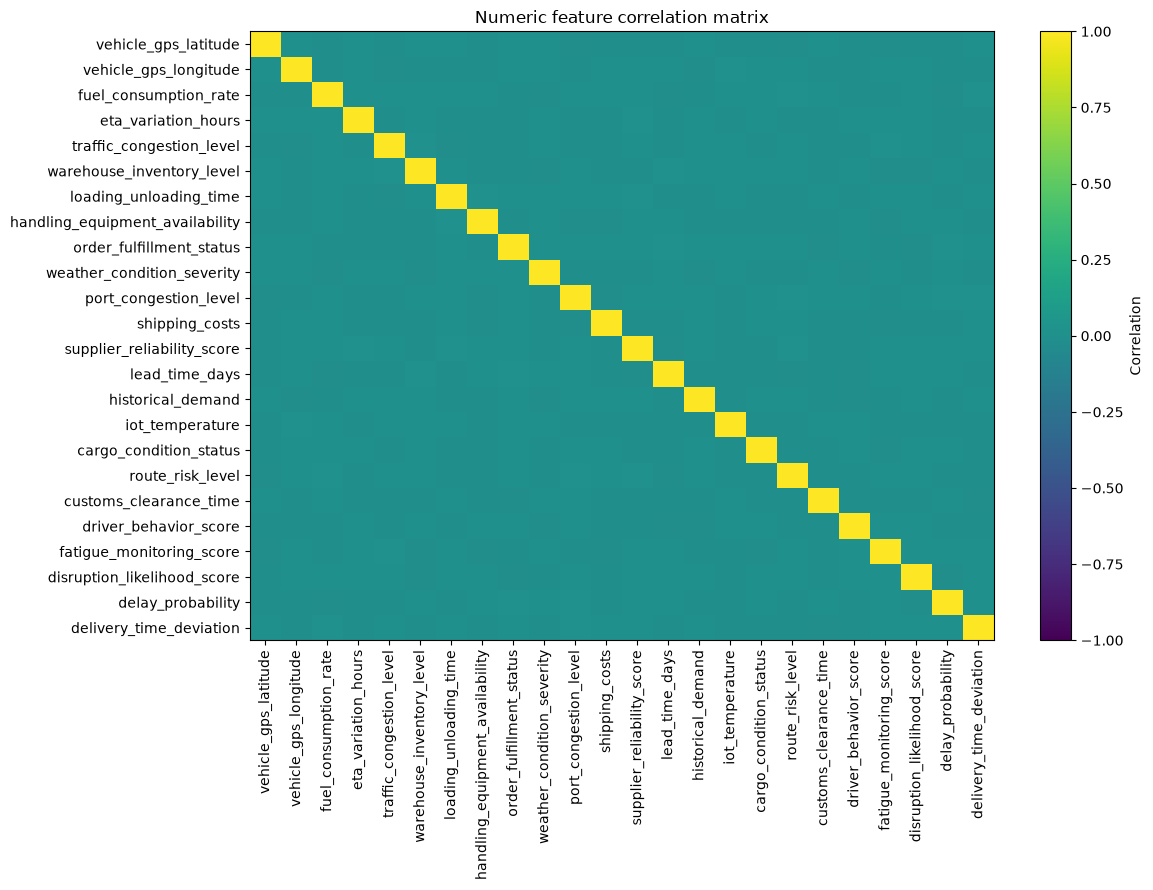

In [8]:
numeric = df.select_dtypes(include="number")
corr = numeric.corr()
display(corr.round(2))
fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(corr, aspect="auto", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr.index)), corr.index)
fig.colorbar(im, ax=ax, label="Correlation")
ax.set_title("Numeric feature correlation matrix")
plt.tight_layout()
plt.show()

## 5. Check whether labels align with scores

In [9]:
display(
    df.groupby("risk_classification", dropna=False)
      [["delay_probability", "disruption_likelihood_score", "eta_variation_hours"]]
      .agg(["count", "mean", "median", "std"])
      .round(3)
)

delay_probability                       \
                                count   mean median    std   
risk_classification                                          
High Risk                       23944  0.699  0.838  0.324   
Low Risk                         3110  0.707  0.847  0.322   
Moderate Risk                    5011  0.696  0.842  0.328   

                    disruption_likelihood_score                       \
                                          count   mean median    std   
risk_classification                                                    
High Risk                                 23944  0.949  0.990  0.076   
Low Risk                                   3110  0.143  0.142  0.089   
Moderate Risk                              5011  0.519  0.531  0.115   

                    eta_variation_hours                       
                                  count   mean median    std  
risk_classification                                           
High Risk                         23944  2.896  3.886  2.276  
Low Risk                           3110  2.883  3.945  2.307  
Moderate Risk                      5011  2.885  3.816  2.245

## Interpretation cautions

Correlation is not causation. Strong relationships between a label and a feature may indicate that the label was generated from that feature, which can create target leakage. Investigate the dataset's provenance before describing a pattern as a real-world operational relationship.